# Unsupervised Clustering of Multilingual Speech

Explore whether standardized acoustic features naturally form language-related groups using custom K-Means and agglomerative average-linkage clustering. The elbow heuristic and PCA visualizations are used for exploratory interpretation. See [experimental analysis](../docs/experimental_analysis.md).

## Load acoustic features

Read the feature table generated by preprocessing.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FEATURES_CSV = Path("../datasets/features_table.csv")
if not FEATURES_CSV.exists():
    raise FileNotFoundError("features_table.csv not found. Generate it in the Feature Extraction step.")

df = pd.read_csv(FEATURES_CSV)
print("Rows:", len(df))
df.head()

Rows: 655


,language,gender,processed_path,zcr_0_mean,zcr_0_std,rms_0_mean,rms_0_std,spec_centroid_0_mean,spec_centroid_0_std,spec_bandwidth_0_mean,...,chroma_7_mean,chroma_7_std,chroma_8_mean,chroma_8_std,chroma_9_mean,chroma_9_std,chroma_10_mean,chroma_10_std,chroma_11_mean,chroma_11_std
0,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.143043,0.104122,0.060331,0.050995,1944.524575,919.463644,1754.496412,...,0.382088,0.312580,0.421553,0.324034,0.427405,0.323133,0.444297,0.339997,0.432369,0.332017
1,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.127733,0.104457,0.056066,0.045961,1789.767551,960.672971,1720.709832,...,0.351764,0.295726,0.408453,0.304481,0.453395,0.308593,0.490467,0.338070,0.453111,0.328605
2,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.105597,0.085899,0.067285,0.058645,1552.156550,834.720557,1646.997488,...,0.409158,0.309259,0.470213,0.315853,0.499733,0.316083,0.514571,0.342777,0.437941,0.318487
3,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.106475,0.084021,0.058888,0.046811,1620.251206,839.514078,1688.599766,...,0.330343,0.290463,0.402950,0.318937,0.448556,0.315676,0.506503,0.328448,0.498888,0.340772
4,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.114301,0.105571,0.050911,0.043566,1645.476240,971.215322,1680.336391,...,0.372121,0.307793,0.399794,0.305063,0.456234,0.318075,0.515569,0.352761,0.470837,0.327594


## Build features and reference labels

Use all 128 numeric descriptors for clustering. True language labels are retained only to evaluate cluster purity and composition.

In [2]:
# Non-feature columns
label_cols = ["language", "gender", "processed_path"]

# All candidate numeric features
feature_cols = [c for c in df.columns if c not in label_cols]

print("Selected features:", len(feature_cols))
print("Example features:", feature_cols[:10])

X = df[feature_cols].values.astype(np.float32)

y_str = df["language"].astype(str).values
classes = np.unique(y_str)
class_to_id = {c: i for i, c in enumerate(classes)}
id_to_class = {i: c for c, i in class_to_id.items()}
y = np.array([class_to_id[v] for v in y_str], dtype=np.int64)

print("X shape:", X.shape)
print("Classes:", classes)

Selected features: 128
Example features: ['zcr_0_mean', 'zcr_0_std', 'rms_0_mean', 'rms_0_std', 'spec_centroid_0_mean', 'spec_centroid_0_std', 'spec_bandwidth_0_mean', 'spec_bandwidth_0_std', 'spec_rolloff_0_mean', 'spec_rolloff_0_std']
X shape: (655, 128)
Classes: ['German' 'Italian' 'Korean' 'Spanish']


## K-Means implementation

Initialize centroids from randomly selected observations (seed 42), assign by squared Euclidean distance, and update means. Empty clusters keep their previous centroid; convergence is checked with `allclose`, with a maximum of 100 iterations. A single initialization is used per k.

In [3]:
def kmeans(X, k=4, max_iter=100, seed=42):
    rng = np.random.default_rng(seed)
    N, D = X.shape

    # Initialize centroids randomly from data
    idx = rng.choice(N, size=k, replace=False)
    centroids = X[idx].copy()

    for _ in range(max_iter):
        # Assign step
        dists = np.sum((X[:, None, :] - centroids[None, :, :])**2, axis=2)
        labels = np.argmin(dists, axis=1)

        # Update step
        new_centroids = np.zeros_like(centroids)
        for j in range(k):
            points = X[labels == j]
            if len(points) > 0:
                new_centroids[j] = points.mean(axis=0)
            else:
                new_centroids[j] = centroids[j]

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return labels, centroids

## Standardization and elbow heuristic

Standardize all 655 clips for this exploratory unsupervised analysis and evaluate within-cluster sum of squares for k=1 through 9. The visual elbow near k=7 is a heuristic, not proof of an optimal cluster count. The number of clusters exceeds the four known languages.

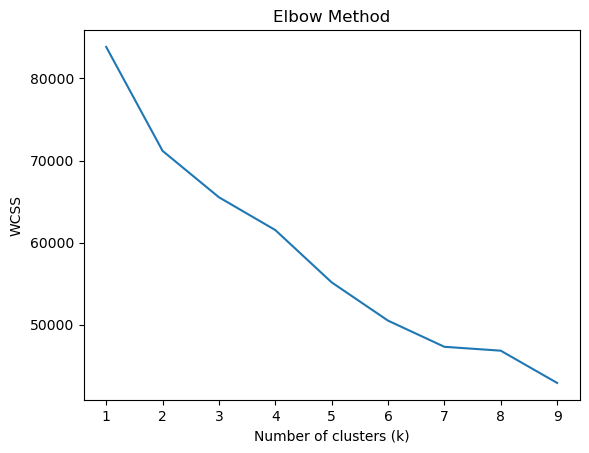

In [4]:
X = df[feature_cols].values.astype(np.float32)

mean = X.mean(axis=0, keepdims=True)
std = X.std(axis=0, keepdims=True) + 1e-8
X_std = (X - mean) / std

X_final = X_std

def compute_wcss(X, labels, centroids):
    wcss = 0
    for i in range(len(centroids)):
        cluster_points = X[labels == i]
        wcss += np.sum((cluster_points - centroids[i])**2)
    return wcss

k_values = range(1, 10)
wcss_values = []

for k in k_values:
    labels, centroids = kmeans(X_final, k=k)
    wcss = compute_wcss(X_final, labels, centroids)
    wcss_values.append(wcss)

plt.figure()
plt.plot(k_values, wcss_values)
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

## Clustering evaluation utilities

Purity sums the majority-language count of each cluster and divides by N. The custom silhouette-like implementation uses squared Euclidean distances and includes the sample itself in the within-cluster mean. Singleton contributions are zero. It is not the conventional Euclidean silhouette score; the values are reported as implemented, not relabeled as standard scores.

In [5]:
def silhouette_score(X, labels):
    N = len(X)
    score = 0

    for i in range(N):
        same_cluster = X[labels == labels[i]]
        other_clusters = [X[labels == c] for c in np.unique(labels) if c != labels[i]]

        if len(same_cluster) <= 1:
            continue

        a = np.mean(np.sum((same_cluster - X[i])**2, axis=1))
        b = min(
            np.mean(np.sum((cluster - X[i])**2, axis=1))
            for cluster in other_clusters
        )

        s = (b - a) / max(a, b)
        score += s

    return score / N


def cluster_purity(y_true, cluster_labels):
    total = len(y_true)
    purity_sum = 0

    for cluster in np.unique(cluster_labels):
        indices = np.where(cluster_labels == cluster)[0]
        true_labels = y_true[indices]
        counts = np.bincount(true_labels)
        purity_sum += np.max(counts)

    return purity_sum / total


def cluster_composition(y_true, cluster_labels):
    results = {}
    for cluster in np.unique(cluster_labels):
        indices = np.where(cluster_labels == cluster)[0]
        true_labels = y_true[indices]
        vals, counts = np.unique(true_labels, return_counts=True)
        results[cluster] = {
            id_to_class[v]: int(c)
            for v, c in zip(vals, counts)
        }
    return results

## Two-dimensional PCA visualization

Compute principal axes via SVD of centered data and project onto the first two. PCA is used only for visualization; clustering takes place in the full standardized feature space.

In [6]:
def pca_2d(X):
    X_centered = X - X.mean(axis=0)
    U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
    components = Vt[:2].T
    return X_centered @ components

## Evaluate cluster structure

Report the custom silhouette, purity, class composition and 2D PCA projection. Cluster identifiers have no intrinsic correspondence to language labels.

In [7]:
def evaluate_clustering(X, y, labels, method_name):
    print(f"\n==================== {method_name} ====================")

    # Silhouette
    sil = silhouette_score(X, labels)
    print("Silhouette Score:", sil)

    # Purity
    purity = cluster_purity(y, labels)
    print("Cluster Purity:", purity)

    # Composition
    comp = cluster_composition(y, labels)
    print("\nCluster Composition:")
    for cluster_id, contents in comp.items():
        print(f"Cluster {cluster_id}:", contents)

    # PCA visualization
    X_2d = pca_2d(X)
    plt.figure()
    for cluster in np.unique(labels):
        plt.scatter(
            X_2d[labels == cluster, 0],
            X_2d[labels == cluster, 1],
            label=f"Cluster {cluster}"
        )
    plt.legend()
    plt.title(f"PCA Visualization - {method_name}")
    plt.show()

    return {
        "method": method_name,
        "silhouette": sil,
        "purity": purity
    }

## K-Means with seven clusters

The saved output yields a silhouette-like score of 0.360533 and purity 0.720611. Four clusters are single-language groups (Italian, Korean, German, Spanish); cluster 2 mixes 84 German, 56 Korean and 84 Spanish clips. Cluster 0 is Korean-majority and cluster 6 Italian-majority. Seven clusters need not correspond to four languages.


==================== K-Means ====================
Silhouette Score: 0.36053306210611924
Cluster Purity: 0.7206106870229008

Cluster Composition:
Cluster 0: {'German': 32, 'Italian': 1, 'Korean': 86}
Cluster 1: {'Italian': 82}
Cluster 2: {'German': 84, 'Korean': 56, 'Spanish': 84}
Cluster 3: {'Korean': 20}
Cluster 4: {'German': 41}
Cluster 5: {'Spanish': 83}
Cluster 6: {'German': 1, 'Italian': 76, 'Korean': 8, 'Spanish': 1}


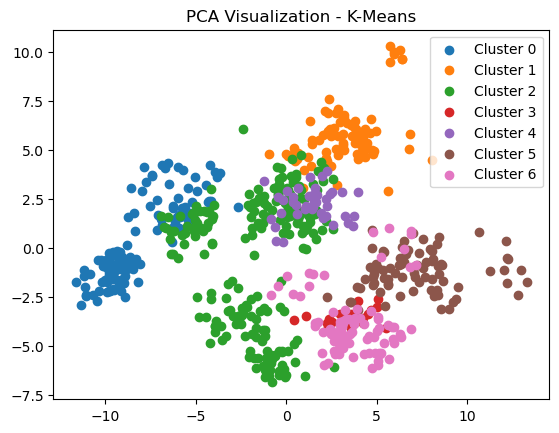

In [8]:
k_optimal = 7  # based on elbow

labels_kmeans, _ = kmeans(X_final, k=k_optimal)
res_kmeans = evaluate_clustering(X_final, y, labels_kmeans, "K-Means")

## Agglomerative average-linkage clustering

Start from singleton clusters and repeatedly merge the pair minimizing mean squared pairwise distance. This is average linkage, not single linkage, and uses squared distances rather than the usual Euclidean distance. The explicit pair search is computationally expensive. With k=4, the saved output places 631 of 655 clips in one mixed cluster, leaving groups of 7, 16 and 1. The resulting imbalance indicates weak alignment with language in this configuration; it does not establish a single-linkage chaining mechanism.

In [9]:
def hierarchical_average_linkage(X, k=4):
    """
    agglomerative clustering with average linkage.
    Note: O(N^3) in worst case (slow for large N), but for ~700 may still run with patience.
    """
    N = X.shape[0]
    clusters = [[i] for i in range(N)]

    # Precompute squared distance matrix
    D2 = np.sum((X[:, None, :] - X[None, :, :])**2, axis=2)

    def avg_dist(c1, c2):
        # average pairwise distance between two clusters
        vals = [D2[i, j] for i in c1 for j in c2]
        return float(np.mean(vals))

    while len(clusters) > k:
        min_dist = np.inf
        merge_i, merge_j = None, None

        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                d = avg_dist(clusters[i], clusters[j])
                if d < min_dist:
                    min_dist = d
                    merge_i, merge_j = i, j

        # Merge clusters
        clusters[merge_i] += clusters[merge_j]
        clusters.pop(merge_j)

    labels = np.zeros(N, dtype=np.int64)
    for cid, cl in enumerate(clusters):
        for idx in cl:
            labels[idx] = cid

    return labels


==================== Hierarchical ====================
Silhouette Score: 0.2764675308545013
Cluster Purity: 0.28396946564885495

Cluster Composition:
Cluster 0: {'German': 158, 'Italian': 145, 'Korean': 169, 'Spanish': 159}
Cluster 1: {'Italian': 7}
Cluster 2: {'Italian': 7, 'Spanish': 9}
Cluster 3: {'Korean': 1}


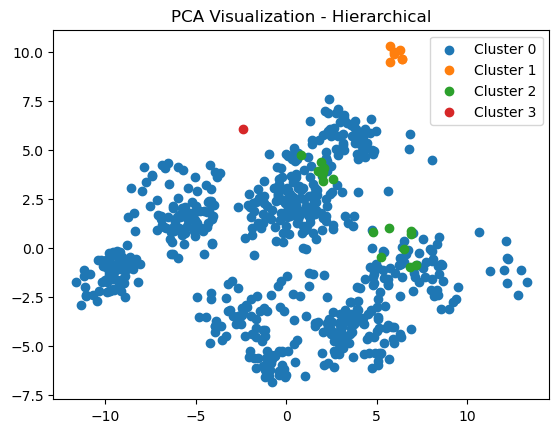

In [ ]:
labels_hier = hierarchical_average_linkage(X_final, k=4)
res_hier = evaluate_clustering(X_final, y, labels_hier, "Hierarchical")

## Compare clustering outcomes

K-Means achieves higher purity and the custom silhouette score than hierarchical clustering in these runs. Because the cluster counts differ (7 vs 4) and purity generally increases with more clusters, this is not a controlled same-k comparison. PCA projections show only two axes and cannot fully describe the original geometry.

In [ ]:
df_cluster_results = pd.DataFrame([res_kmeans, res_hier])
df_cluster_results


,method,silhouette,purity
0,K-Means,0.360533,0.720611
1,Hierarchical,0.276468,0.283969


## Export clustering metrics

Save the comparison table for the evaluation notebook.

In [ ]:
from pathlib import Path
out_csv = Path("../results/clustering_results_summary.csv")
df_cluster_results.to_csv(out_csv, index=False)
print("Saved:", out_csv.resolve())


Saved: C:\Users\Farzam\MLProject\clustering_results_summary.csv


## Conclusion

The seven-cluster K-Means solution shows partial alignment with language labels, while the four-cluster hierarchical solution is dominated by one mixed cluster. Clustering is performed on 128 standardized descriptors rather than the six PCA components used for classification; the two tasks therefore do not have identical representations or evaluation protocols. The elbow selection, different cluster counts, nonstandard silhouette calculation and single initialization limit the comparison. Speaker, gender and recording characteristics are possible explanations for subclusters, but were not separately tested. t-SNE was considered in the analysis but is not implemented here.